In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from tqdm import tqdm
import warnings
warnings.filterwarnings("ignore")

from server import lmd_simulator

In [ ]:
def run_param_sweep(config, results_path):
    with open(results_path, "w") as f:
        f.write(
            "num_ugvs,ugv_range,maze_loop_percentage,"
            "tasks_completed,distance_traveled,energy_consumed,avg_task_completion_time\n"
        )
        # nested tqdm bars to monitor progress
        for num_ugvs in tqdm(range(3, 8), desc="Num UGVs"):
            for maze_loop_percentage in tqdm(range(50, 91, 10),
                                             desc="Maze Loop %",
                                             leave=False):
                for ugv_range in tqdm(range(1500, 5001, 500),
                                      desc="UGV Range",
                                      leave=False):
                    print("Num UGVs, UGV Range, Maze LP:", num_ugvs, ugv_range, maze_loop_percentage)
                    config["fleet"]['ugv']["count"] = num_ugvs
                    config["fleet"]['ugv']["range"] = ugv_range
                    config["maze"]["maze_loop_percentage"] = maze_loop_percentage

                    results = lmd_simulator(config)
                    tasks_completed = results["tasks_completed"]
                    distance_traveled = results["distance_traveled"]
                    energy_consumed = results["energy_consumed"]
                    avg_task_completion_time = results["avg_task_completion_time"]

                    results_line = (
                        f"{num_ugvs}, {ugv_range}, {maze_loop_percentage}, "
                        f"{tasks_completed}, {distance_traveled}, "
                        f"{energy_consumed}, {avg_task_completion_time}\n"
                    )
                    f.write(results_line)


In [ ]:
config_file = f"runs/dijkstra/config.yaml"

config = yaml.safe_load(open(config_file, "r"))
results_path = f"runs/dijkstra/param_sweep_bms.csv"
run_param_sweep(config, results_path)

In [ ]:
config_file = f"runs/sarsa/config.yaml"

config = yaml.safe_load(open(config_file, "r"))
results_path = f"runs/sarsa/param_sweep_bms.csv"
run_param_sweep(config, results_path)

In [ ]:
config_file = f"runs/dqn/config.yaml"

config = yaml.safe_load(open(config_file, "r"))
results_path = f"runs/dqn/param_sweep_bms.csv"
run_param_sweep(config, results_path)

In [ ]:
def plot_param(results1, results2, results3, results1_, results2_, results3_, param):
    grouped1 = results1.groupby(param).mean().reset_index()
    grouped2 = results2.groupby(param).mean().reset_index()
    grouped3 = results3.groupby(param).mean().reset_index()
    grouped1_ = results1_.groupby(param).mean().reset_index()
    grouped2_ = results2_.groupby(param).mean().reset_index()
    grouped3_ = results3_.groupby(param).mean().reset_index()

    fig, axes = plt.subplots(3, 1, figsize=(8, 12), sharex=True)

    axes[0].plot(grouped1[param], grouped1['tasks_completed'], label='Dijkstra (No BMS)', color='red', linestyle='--')
    axes[0].plot(grouped2[param], grouped2['tasks_completed'], label='SARSA (No BMS)', color='blue', linestyle='--')
    axes[0].plot(grouped3[param], grouped3['tasks_completed'], label='DQN (No BMS)', color='green', linestyle='--')
    axes[0].plot(grouped1_[param], grouped1_['tasks_completed'], label='Dijkstra (BMS)', color='red')
    axes[0].plot(grouped2_[param], grouped2_['tasks_completed'], label='SARSA (BMS)', color='blue')
    axes[0].plot(grouped3_[param], grouped3_['tasks_completed'], label='DQN (BMS)', color='green')
    axes[0].set_title(f'Tasks Completed vs {param}')
    axes[0].set_ylabel('Tasks Completed')
    axes[0].legend()

    axes[1].plot(grouped1[param], grouped1['energy_consumed'], label='Dijkstra (No BMS)', color='red', linestyle='--')
    axes[1].plot(grouped2[param], grouped2['energy_consumed'], label='SARSA (No BMS)', color='blue', linestyle='--')
    axes[1].plot(grouped3[param], grouped3['energy_consumed'], label='DQN (No BMS)', color='green', linestyle='--')
    axes[1].plot(grouped1_[param], grouped1_['energy_consumed'], label='Dijkstra (BMS)', color='red')
    axes[1].plot(grouped2_[param], grouped2_['energy_consumed'], label='SARSA (BMS)', color='blue')
    axes[1].plot(grouped3_[param], grouped3_['energy_consumed'], label='DQN (BMS)', color='green')
    axes[1].set_title(f'Energy Consumed vs {param}')
    axes[1].set_ylabel('Energy Consumed')
    axes[1].legend()

    axes[2].plot(grouped1[param], grouped1['avg_task_completion_time'], label='Dijkstra (No BMS)', color='red', linestyle='--')
    axes[2].plot(grouped2[param], grouped2['avg_task_completion_time'], label='SARSA (No BMS)', color='blue', linestyle='--')
    axes[2].plot(grouped3[param], grouped3['avg_task_completion_time'], label='DQN (No BMS)', color='green', linestyle='--')
    axes[2].plot(grouped1_[param], grouped1_['avg_task_completion_time'], label='Dijkstra (BMS)', color='red')
    axes[2].plot(grouped2_[param], grouped2_['avg_task_completion_time'], label='SARSA (BMS)', color='blue')
    axes[2].plot(grouped3_[param], grouped3_['avg_task_completion_time'], label='DQN (BMS)', color='green')
    axes[2].set_title(f'Task Completion Time vs {param}')
    axes[2].set_ylabel('Task Completion Time')
    axes[2].legend()

    plt.tight_layout()
    plt.show()

In [ ]:
dij_df = pd.read_csv("runs/dijkstra/param_sweep.csv")
sarsa_df = pd.read_csv(f"runs/sarsa/param_sweep.csv")
dqn_df = pd.read_csv(f"runs/dqn/param_sweep.csv")
dij_df_bms = pd.read_csv("runs/dijkstra/param_sweep_bms.csv")
sarsa_df_bms = pd.read_csv(f"runs/sarsa/param_sweep_bms.csv")
dqn_df_bms = pd.read_csv(f"runs/dqn/param_sweep_bms.csv")
plot_param(dij_df, sarsa_df, dqn_df, dij_df_bms, sarsa_df_bms, dqn_df_bms, "num_ugvs")

In [ ]:
dij_df = pd.read_csv("runs/dijkstra/param_sweep.csv")
sarsa_df = pd.read_csv(f"runs/sarsa/param_sweep.csv")
dqn_df = pd.read_csv(f"runs/dqn/param_sweep.csv")
dij_df_bms = pd.read_csv("runs/dijkstra/param_sweep_bms.csv")
sarsa_df_bms = pd.read_csv(f"runs/sarsa/param_sweep_bms.csv")
dqn_df_bms = pd.read_csv(f"runs/dqn/param_sweep_bms.csv")
plot_param(dij_df, sarsa_df, dqn_df, dij_df_bms, sarsa_df_bms, dqn_df_bms, "maze_loop_percentage")

In [ ]:
dij_df = pd.read_csv("runs/dijkstra/param_sweep.csv")
sarsa_df = pd.read_csv(f"runs/sarsa/param_sweep.csv")
dqn_df = pd.read_csv(f"runs/dqn/param_sweep.csv")
dij_df_bms = pd.read_csv("runs/dijkstra/param_sweep_bms.csv")
sarsa_df_bms = pd.read_csv(f"runs/sarsa/param_sweep_bms.csv")
dqn_df_bms = pd.read_csv(f"runs/dqn/param_sweep_bms.csv")
plot_param(dij_df, sarsa_df, dqn_df, dij_df_bms, sarsa_df_bms, dqn_df_bms, "ugv_range")

# Path Planning Testing

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from tqdm import tqdm
import warnings
warnings.filterwarnings("ignore")

from server_pp import lmd_simulator

In [2]:
def run_param_sweep(config, results_path):
    with open(results_path, "w") as f:
        f.write("num_centroids,std_dev,maze_loop_percentage,time_elapsed\n")
        # nested tqdm bars to monitor progress
        for tf_centroids in tqdm(range(4,6), desc="Traffic Centroids"):
            for tf_std in tqdm(np.arange(1,3, 0.2),
                                    desc="Traffic Std Dev",
                                    leave=False):
                for maze_loop_percentage in tqdm(range(50, 91, 10),
                                                desc="Maze Loop %",
                                                leave=False):
                    print("tf_centroids, tf_std, maze_lp:", tf_centroids, tf_std, maze_loop_percentage)
                    config["traffic"]["num_centroids"] = tf_centroids
                    config["traffic"]["std_dev"] = tf_std
                    config["maze"]["maze_loop_percentage"] = maze_loop_percentage

                    results = lmd_simulator(config)
                    for time_elapsed in results:
                        results_line = (
                            f"{tf_centroids}, {tf_std}, {maze_loop_percentage}, "
                            f"{time_elapsed}\n"
                        )
                        f.write(results_line)


In [3]:
config_file = f"runs/dijkstra/config.yaml"

config = yaml.safe_load(open(config_file, "r"))
results_path = f"runs/dijkstra/pp_param_sweep.csv"
run_param_sweep(config, results_path)

Traffic Centroids:   0%|          | 0/4 [00:00<?, ?it/s]


tf_centroids, tf_std, maze_lp: 1 1.0 50


tf_centroids, tf_std, maze_lp: 1 1.0 60


tf_centroids, tf_std, maze_lp: 1 1.0 70


tf_centroids, tf_std, maze_lp: 1 1.0 80


...

tf_centroids, tf_std, maze_lp: 4 2.8 60


tf_centroids, tf_std, maze_lp: 4 2.8 70


tf_centroids, tf_std, maze_lp: 4 2.8 80


tf_centroids, tf_std, maze_lp: 4 2.8 90




Traffic Centroids: 100%|██████████| 4/4 [15:26<00:00, 231.71s/it]


In [3]:
config_file = f"runs/sarsa/config.yaml"

config = yaml.safe_load(open(config_file, "r"))
results_path = f"runs/sarsa/pp_param_sweep.csv"
run_param_sweep(config, results_path)

Traffic Centroids:   0%|          | 0/4 [00:00<?, ?it/s]


tf_centroids, tf_std, maze_lp: 1 1.0 50
Policy loaded from runs/sarsa/policy.pkl


tf_centroids, tf_std, maze_lp: 1 1.0 60
Policy loaded from runs/sarsa/policy.pkl


tf_centroids, tf_std, maze_lp: 1 1.0 70
Policy loaded from runs/sarsa/policy.pkl


tf_centroids, tf_std, maze_lp: 1 1.0 80
Policy loaded from runs/sarsa/policy.pkl


...

tf_centroids, tf_std, maze_lp: 4 2.8 60
Policy loaded from runs/sarsa/policy.pkl


tf_centroids, tf_std, maze_lp: 4 2.8 70
Policy loaded from runs/sarsa/policy.pkl


tf_centroids, tf_std, maze_lp: 4 2.8 80
Policy loaded from runs/sarsa/policy.pkl


tf_centroids, tf_std, maze_lp: 4 2.8 90
Policy loaded from runs/sarsa/policy.pkl




Traffic Centroids: 100%|██████████| 4/4 [17:38<00:00, 264.65s/it]


In [3]:
config_file = f"runs/dynaq/config.yaml"

config = yaml.safe_load(open(config_file, "r"))
results_path = f"runs/dynaq/pp_param_sweep.csv"
run_param_sweep(config, results_path)

Traffic Centroids:   0%|          | 0/2 [00:00<?, ?it/s]


tf_centroids, tf_std, maze_lp: 4 1.0 50
Policy loaded from runs/dynaq/policy.pkl


tf_centroids, tf_std, maze_lp: 4 1.0 60
Policy loaded from runs/dynaq/policy.pkl


tf_centroids, tf_std, maze_lp: 4 1.0 70
Policy loaded from runs/dynaq/policy.pkl


tf_centroids, tf_std, maze_lp: 4 1.0 80
Policy loaded from runs/dynaq/policy.pkl


...

tf_centroids, tf_std, maze_lp: 5 2.8 60
Policy loaded from runs/dynaq/policy.pkl


tf_centroids, tf_std, maze_lp: 5 2.8 70
Policy loaded from runs/dynaq/policy.pkl


tf_centroids, tf_std, maze_lp: 5 2.8 80
Policy loaded from runs/dynaq/policy.pkl


tf_centroids, tf_std, maze_lp: 5 2.8 90
Policy loaded from runs/dynaq/policy.pkl




Traffic Centroids: 100%|██████████| 2/2 [16:48<00:00, 504.50s/it]


In [3]:
config_file = f"runs/dqn/config.yaml"

config = yaml.safe_load(open(config_file, "r"))
results_path = f"runs/dqn/pp_param_sweep.csv"
run_param_sweep(config, results_path)

Traffic Centroids:   0%|          | 0/2 [00:00<?, ?it/s]


tf_centroids, tf_std, maze_lp: 4 1.0 50
QNetwork(
  (network): Sequential(
    (0): Linear(in_features=9, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=9, bias=True)
    (3): ReLU()
    (4): Linear(in_features=9, out_features=5, bias=True)
  )
)


tf_centroids, tf_std, maze_lp: 4 1.0 60
QNetwork(
  (network): Sequential(
    (0): Linear(in_features=9, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=9, bias=True)
    (3): ReLU()
    (4): Linear(in_features=9, out_features=5, bias=True)
  )
)


tf_centroids, tf_std, maze_lp: 4 1.0 70
QNetwork(
  (network): Sequential(
    (0): Linear(in_features=9, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=9, bias=True)
    (3): ReLU()
    (4): Linear(in_features=9, out_features=5, bias=True)
  )
)


tf_centroids, tf_std, maze_lp: 4 1.0 80
QNetwork(
  (network): Sequential(
    (0): Linear(in_features=9, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=9, bias=True)
    (3): ReLU()
    (4): Linear(in_features=9, out_features=5, bias=True)
  )
)


...

tf_centroids, tf_std, maze_lp: 5 2.8 60
QNetwork(
  (network): Sequential(
    (0): Linear(in_features=9, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=9, bias=True)
    (3): ReLU()
    (4): Linear(in_features=9, out_features=5, bias=True)
  )
)


tf_centroids, tf_std, maze_lp: 5 2.8 70
QNetwork(
  (network): Sequential(
    (0): Linear(in_features=9, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=9, bias=True)
    (3): ReLU()
    (4): Linear(in_features=9, out_features=5, bias=True)
  )
)


tf_centroids, tf_std, maze_lp: 5 2.8 80
QNetwork(
  (network): Sequential(
    (0): Linear(in_features=9, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=9, bias=True)
    (3): ReLU()
    (4): Linear(in_features=9, out_features=5, bias=True)
  )
)


tf_centroids, tf_std, maze_lp: 5 2.8 90
QNetwork(
  (network): Sequential(
    (0): Linear(in_features=9, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=9, bias=True)
    (3): ReLU()
    (4): Linear(in_features=9, out_features=5, bias=True)
  )
)




Traffic Centroids: 100%|██████████| 2/2 [06:40<00:00, 200.41s/it]


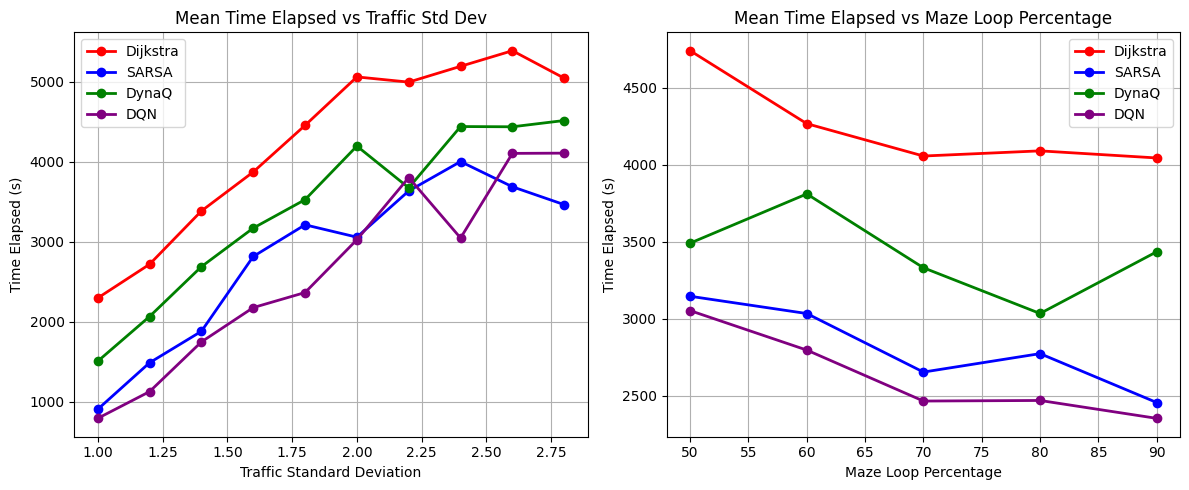

In [7]:
def plot_time_vs_params(df_dij, df_sarsa, df_dynaq, df_dqn):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    # # Group by num_centroids (traffic centroids)
    # grouped_centroids_dij = df_dij.groupby('num_centroids').mean().reset_index()
    # grouped_centroids_sarsa = df_sarsa.groupby('num_centroids').mean().reset_index()
    # grouped_centroids_dynaq = df_dynaq.groupby('num_centroids').mean().reset_index()
    # axes[0].plot(grouped_centroids_dij['num_centroids'], grouped_centroids_dij['time_elapsed'], 'o-', linewidth=2, label='Dijkstra', color='red')
    # axes[0].plot(grouped_centroids_sarsa['num_centroids'], grouped_centroids_sarsa['time_elapsed'], 'o-', linewidth=2, label='SARSA', color='blue')
    # axes[0].plot(grouped_centroids_dynaq['num_centroids'], grouped_centroids_dynaq['time_elapsed'], 'o-', linewidth=2, label='DynaQ', color='green')
    # axes[0].set_title('Mean Time Elapsed vs Traffic Centroids')
    # axes[0].set_xlabel('Number of Traffic Centroids')
    # axes[0].set_ylabel('Time Elapsed (s)')
    # axes[0].grid(True)
    # axes[0].legend()
    df_dij = df_dij[df_dij['num_centroids'] == 4]
    df_sarsa = df_sarsa[df_sarsa['num_centroids'] == 4]
    df_dynaq = df_dynaq[df_dynaq['num_centroids'] == 4]
    df_dqn = df_dqn[df_dqn['num_centroids'] == 4]

    df_dij['time_elapsed'] = df_dij['time_elapsed'].clip(upper=20000)
    df_sarsa['time_elapsed'] = df_sarsa['time_elapsed'].clip(upper=20000)
    df_dynaq['time_elapsed'] = df_dynaq['time_elapsed'].clip(upper=20000)
    df_dqn['time_elapsed'] = df_dqn['time_elapsed'].clip(upper=20000)
    
    # Group by std_dev (traffic std)
    grouped_std_dij = df_dij.groupby('std_dev').mean().reset_index()
    grouped_std_sarsa = df_sarsa.groupby('std_dev').mean().reset_index()
    grouped_std_dynaq = df_dynaq.groupby('std_dev').mean().reset_index()
    grouped_std_dqn = df_dqn.groupby('std_dev').mean().reset_index()
    axes[0].plot(grouped_std_dij['std_dev'], grouped_std_dij['time_elapsed'], 'o-', linewidth=2, label='Dijkstra', color='red')
    axes[0].plot(grouped_std_sarsa['std_dev'], grouped_std_sarsa['time_elapsed'], 'o-', linewidth=2, label='SARSA', color='blue')
    axes[0].plot(grouped_std_dynaq['std_dev'], grouped_std_dynaq['time_elapsed'], 'o-', linewidth=2, label='DynaQ', color='green')
    axes[0].plot(grouped_std_dqn['std_dev'], grouped_std_dqn['time_elapsed'], 'o-', linewidth=2, label='DQN', color='purple')
    axes[0].set_title('Mean Time Elapsed vs Traffic Std Dev')
    axes[0].set_xlabel('Traffic Standard Deviation')
    axes[0].set_ylabel('Time Elapsed (s)')
    axes[0].grid(True)
    axes[0].legend()
    
    # Group by maze_loop_percentage
    grouped_maze_dij = df_dij.groupby('maze_loop_percentage').mean().reset_index()
    grouped_maze_sarsa = df_sarsa.groupby('maze_loop_percentage').mean().reset_index()
    grouped_maze_dynaq = df_dynaq.groupby('maze_loop_percentage').mean().reset_index()
    grouped_maze_dqn = df_dqn.groupby('maze_loop_percentage').mean().reset_index()
    axes[1].plot(grouped_maze_dij['maze_loop_percentage'], grouped_maze_dij['time_elapsed'], 'o-', linewidth=2, label='Dijkstra', color='red')
    axes[1].plot(grouped_maze_sarsa['maze_loop_percentage'], grouped_maze_sarsa['time_elapsed'], 'o-', linewidth=2, label='SARSA', color='blue')
    axes[1].plot(grouped_maze_dynaq['maze_loop_percentage'], grouped_maze_dynaq['time_elapsed'], 'o-', linewidth=2, label='DynaQ', color='green')
    axes[1].plot(grouped_maze_dqn['maze_loop_percentage'], grouped_maze_dqn['time_elapsed'], 'o-', linewidth=2, label='DQN', color='purple')
    axes[1].set_title('Mean Time Elapsed vs Maze Loop Percentage')
    axes[1].set_xlabel('Maze Loop Percentage')
    axes[1].set_ylabel('Time Elapsed (s)')
    axes[1].grid(True)
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()

# First we need to read the SARSA data since df_sarsa doesn't exist yet
df_dij = pd.read_csv("runs/dijkstra/pp_param_sweep.csv")
df_sarsa = pd.read_csv("runs/sarsa/pp_param_sweep.csv")
df_dynaq = pd.read_csv("runs/dynaq/pp_param_sweep.csv")
df_dqn = pd.read_csv("runs/dqn/pp_param_sweep.csv")

# Now we can plot with the correct data
plot_time_vs_params(df_dij, df_sarsa, df_dynaq, df_dqn)

In [4]:
df_dij = pd.read_csv("runs/dijkstra/pp_param_sweep.csv")
df_sarsa = pd.read_csv("runs/sarsa/pp_param_sweep.csv")
df_dynaq = pd.read_csv("runs/dynaq/pp_param_sweep.csv")
df_dqn = pd.read_csv("runs/dqn/pp_param_sweep.csv")

df_dij = df_dij[df_dij['num_centroids'] == 4]
df_sarsa = df_sarsa[df_sarsa['num_centroids'] == 4]
df_dynaq = df_dynaq[df_dynaq['num_centroids'] == 4]
df_dqn = df_dqn[df_dqn['num_centroids'] == 4]

df_dij['time_elapsed'] = df_dij['time_elapsed'].clip(upper=20000)
df_sarsa['time_elapsed'] = df_sarsa['time_elapsed'].clip(upper=20000)
df_dynaq['time_elapsed'] = df_dynaq['time_elapsed'].clip(upper=20000)
df_dqn['time_elapsed'] = df_dqn['time_elapsed'].clip(upper=20000)

print("Average time elapsed (Dijkstra):", df_dij['time_elapsed'].mean())
print("Average time elapsed (SARSA):", df_sarsa['time_elapsed'].mean())
print("Average time elapsed (DynaQ):", df_dynaq['time_elapsed'].mean())
print("Average time elapsed (DQN):", df_dqn['time_elapsed'].mean())

Average time elapsed (Dijkstra): 4240.15
Average time elapsed (SARSA): 2813.85
Average time elapsed (DynaQ): 3421.25
Average time elapsed (DQN): 2628.8
